<a href="https://colab.research.google.com/github/jasminebarry/BASC0005/blob/main/w05_distributions_and_basic_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sampling and Distributions

## *Workshop 5*  [![Open In Colab](https://github.com/oballinger/BASC0005/blob/main/colab-badge.png?raw=1)](https://colab.research.google.com/github/oballinger/BASC0005/blob/main/notebooks/W05.%20Distributions%20and%20Basic%20Statistics.ipynb)

For the next few weeks we'll be working with an extract of the U.S. Census Bureau's [Current Population Survey (CPS)](https://www.census.gov/programs-surveys/cps.html): a large, monthly household survey that is the source of official U.S. statistics on employment, earnings and union membership.

This workshop follows the lecture: we start with **where the data came from** (populations, samples, selection bias), then **summarise** it, and then use the **Central Limit Theorem** and the **standard error** to see how much a single sample can tell us about a population.

### Aims

- Tell a **population** from a **sample**, and spot **selection bias**
- Choose appropriate summary statistics (mean, median, mode, variance, standard deviation) for different variables
- Plot and interpret distributions
- Build intuition for the **Central Limit Theorem** by simulation, using union membership (as in the lecture)
- Use the **standard error** and the 68-95-99.7 rule

The workshop takes roughly two hours.

## Setup

We'll use `pandas` for data, `numpy` for maths and random numbers, and `matplotlib`/`seaborn` for plots.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

sns.set_theme(style="white", font_scale=1.2)
plt.rcParams["figure.figsize"] = (10, 5)

# Fix the random seed, so your numbers match the ones on the website.
# Change the seed (or delete it) to see how the results vary from run to run.
np.random.seed(42)

In [6]:
cps = pd.read_csv("https://storage.googleapis.com/qm2/wk7/cps.csv")
cps.head()

,year,state,age,sex,race,sch,ind,union,incwage,realhrwage,occupation
0,1990,36,58,1,3,12.0,871,0.0,14200.0,12.269874,Office and Admin Support
1,2009,5,28,1,1,12.0,8660,1.0,17680.0,8.635149,Office and Admin Support
2,1990,36,37,1,1,14.0,380,1.0,28000.0,21.169851,.
3,1990,6,34,1,1,18.0,740,1.0,27500.0,20.447746,Computer and Math Technicians
4,1981,51,38,1,4,13.0,798,NaN,17000.0,18.892282,Managers


The dataframe has one row per person and these columns:

| column | meaning |
|---|---|
| `year` | survey year |
| `state` | state (FIPS code) |
| `age` | age in years |
| `sex` | 1 = male, 2 = female |
| `race` | 1 = White non-Hispanic, 2 = Black non-Hispanic, 3 = Hispanic, 4 = Other non-Hispanic |
| `sch` | years of schooling (12 = high school, 13 = some college, 14 = associate's, 16 = BA, 18 = advanced degree) |
| `ind` | [industry code](https://www.census.gov/naics/) |
| `union` | 0 = not asked (N/A), 1 = not covered by a union, 2 = member of a labour union, 3 = covered by a union but not a member |
| `incwage` | annual wage and salary income ($) |
| `realhrwage` | real hourly wage ($) |
| `occupation` | occupation group (`.` = missing) |

## 1. Populations, samples and selection bias

In the lecture we met Abraham Wald and the bombers: the Navy's data only contained planes that **made it back**, so the bullet holes showed where a plane *could* be hit and survive. The lesson: before computing anything, ask **how did this row end up in my dataset?**

- A **population** is the set of all relevant measurements (e.g. all U.S. workers).
- A **sample** is a group of observations drawn in some way from that population (e.g. the people the CPS interviewed).
- If the sample is not drawn at random, we risk **selection bias**; **survivorship bias** is a special case.

The CPS is a carefully designed random sample of households. But *this extract* has also been filtered by whoever prepared it. Let's check who is actually in it.

In [7]:
cps[["year", "age", "incwage", "realhrwage"]].agg(["min", "max"])

,year,age,incwage,realhrwage
min,1981,25,15.0,2.00000
max,2013,64,1259999.0,294610.96875


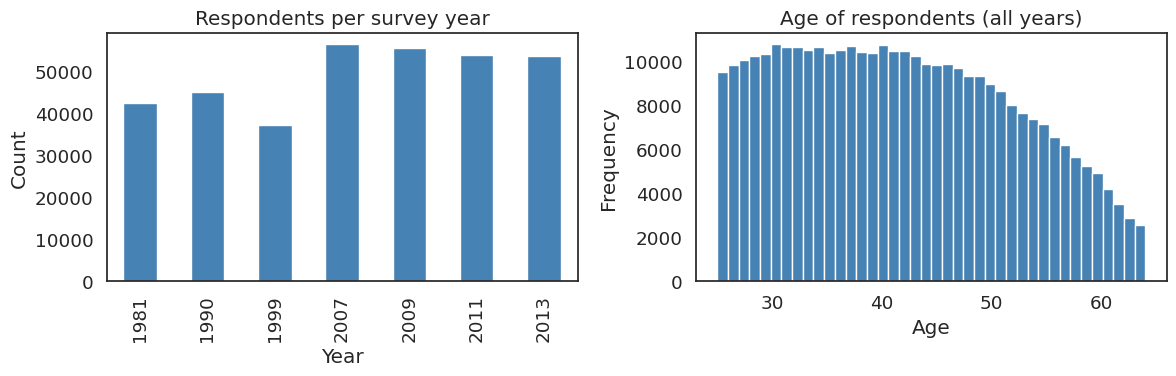

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cps["year"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Respondents per survey year", xlabel="Year", ylabel="Count")
cps["age"].plot.hist(bins=40, ax=axes[1], color="steelblue", edgecolor="white")
axes[1].set(title="Age of respondents (all years)", xlabel="Age")
plt.tight_layout()
plt.show()

### Exercise: who is in the sample, and who isn't?

Using the table and plots above, plus the CPS [methodology page](https://www.census.gov/programs-surveys/cps/technical-documentation/methodology.html):

1. Nobody in this file is under 25 or over 64, and everyone has **positive wage income**. So what is the *population* this sample can speak about? Is it "Americans"? "American workers"?
2. Who is systematically missing (think: students, retirees, the unemployed, the self-employed, people without a fixed address)?
3. Suppose a journalist uses this file to report "the average American earns \$X". What's wrong with that sentence?
4. How is the CPS sample drawn in the first place? Where could selection bias still creep in even with a random design (hint: who *answers* a survey)?

*Write your answers in the markdown cell below.*

*Your answers here.*

## 2. Summary statistics

We'll focus on the most recent survey wave, **2013**. `describe()` gives the count, mean, standard deviation, min/max and quartiles (the 50% quartile is the **median**) of every numeric column.

In [9]:
df = cps[cps["year"] == 2013].copy()
df["income"] = df["incwage"] / 1000   # income in $ thousands: easier to read
df.describe().round(2)

,year,state,age,sex,race,sch,ind,union,incwage,realhrwage,income
count,53790.0,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00
mean,2013.0,27.89,42.91,1.49,1.69,13.93,6363.97,0.19,51821.86,24.38,51.82
std,0.0,16.09,10.56,0.50,1.02,2.74,2612.37,0.46,60163.45,151.90,60.16
min,2013.0,1.00,25.00,1.00,1.00,0.00,170.00,0.00,38.00,2.01,0.04
25%,2013.0,12.00,34.00,1.00,1.00,12.00,4870.00,0.00,24000.00,12.17,24.00
50%,2013.0,27.00,43.00,1.00,1.00,13.00,7380.00,0.00,40000.00,18.44,40.00
75%,2013.0,42.00,51.00,2.00,3.00,16.00,8190.00,0.00,63000.00,28.12,63.00
max,2013.0,56.00,64.00,2.00,4.00,18.00,9590.00,3.00,1102999.00,34760.80,1103.00


### Exercise

From the table above:

1. What is the median hourly wage (`realhrwage`)? And the mean? Why are they different?
2. What is the average age?
3. Are there more men or women? (Hint: `sex` is 1 or 2, so its mean tells you the share of women... how?)
4. Interpret the mean of the `race` column. Does it mean anything?

*Your answers here.*

1. Mean is double the median, likely skewed by exceptionally high earners.
2. 42 - greater proportion of older workers.
3. Slightly more men (1), but mostly even approx 50:50 split.
4. No it is categorical.

### Categorical variables: use the mode

`race`, `sex`, `union` and `occupation` are **categorical**: the numbers are labels, not quantities, so their mean is meaningless. For categorical variables the most representative value is the **mode** (the most common category). Telling pandas a column is categorical stops it from computing nonsense:

In [10]:
for col in ["race", "sex", "union"]:
    df[col] = df[col].astype("category")

df["race"].describe()   # count, number of unique values, top (= mode) and its frequency

,race
count,53790
unique,4
top,1
freq,34662


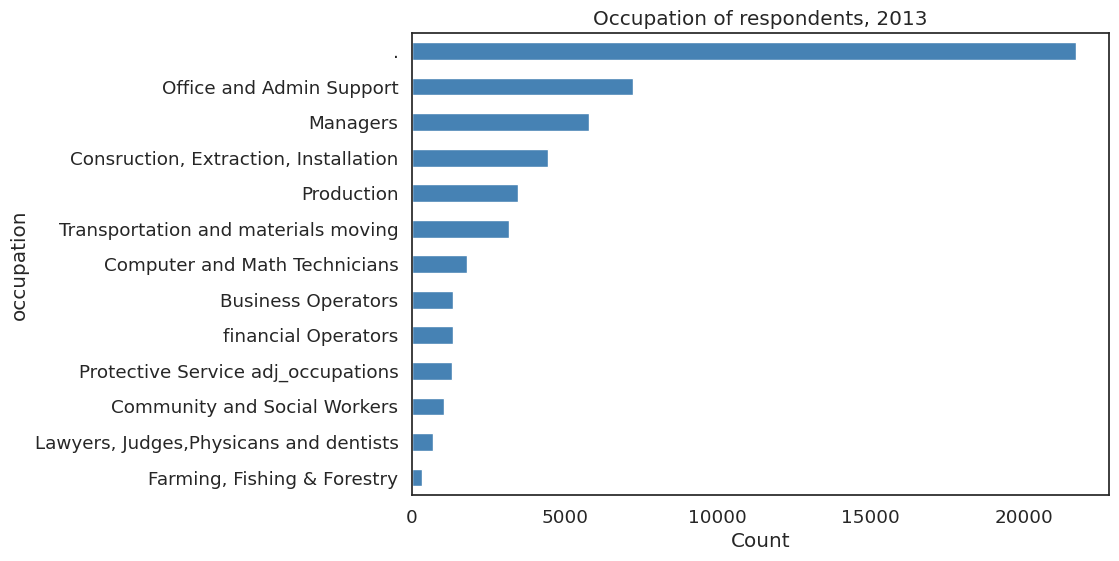

In [11]:
occ = df["occupation"].value_counts()
occ.sort_values().plot.barh(color="steelblue", figsize=(9, 6))
plt.title("Occupation of respondents, 2013")
plt.xlabel("Count")
plt.show()

### Exercise

1. What is the modal (most common) occupation? Be careful: what does the `.` category mean, and should it count?
2. Roughly what share of 2013 respondents have a missing occupation? If people with a missing occupation differ systematically from the rest (e.g. they earn less), what happens to any analysis that silently drops them?

In [12]:
# your code here
# no need for code, from figure, mode is office and admin support
# excluding . which is missing values.

# calc value for . and divide by total x 100 for it's share
# dropping them is less representative, esp. if they represent
# lower paid service industry jobs...

unknown = occ['.']
total = occ.sum()
unknown_share = (unknown / total) * 100
print(unknown_share)
# 40%, a large proportion

40.34207101691764


### Mean vs median: skewed distributions

Income is the classic **skewed** variable: most people earn a moderate amount, a few earn a lot. Let's plot its distribution with a **histogram** and mark the mean and median.

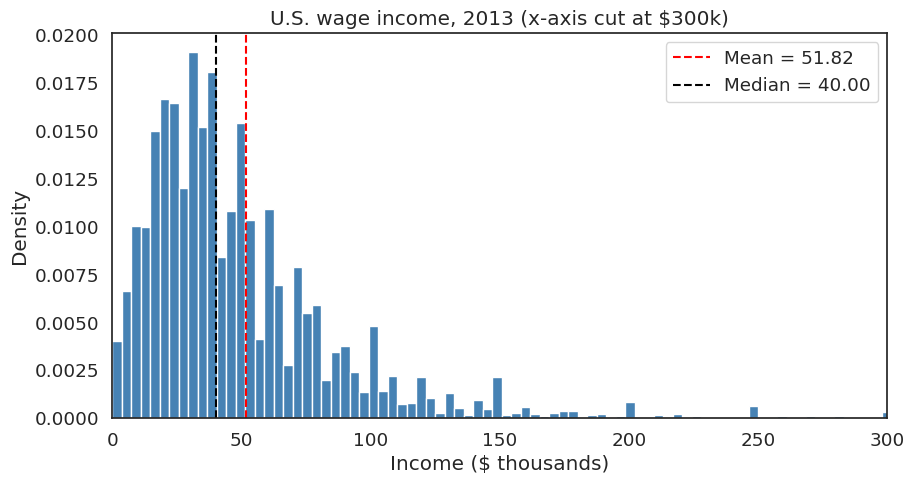

In [13]:
def plot_histogram(variable, bins=50, xlab="", title="", xlim=None):
    # Histogram of a pandas Series with its mean and median marked
    plt.hist(variable, bins=bins, edgecolor="white", density=True, color="steelblue")
    plt.axvline(variable.mean(), color="red", linestyle="--", label=f"Mean = {variable.mean():.2f}")
    plt.axvline(variable.median(), color="black", linestyle="--", label=f"Median = {variable.median():.2f}")
    if xlim is not None:
        plt.xlim(xlim)
    plt.xlabel(xlab)
    plt.ylabel("Density")
    plt.title(title)
    plt.legend()
    plt.show()

plot_histogram(df["income"], bins=300, xlab="Income ($ thousands)",
               title="U.S. wage income, 2013 (x-axis cut at $300k)", xlim=(0, 300))

### Exercise

1. Why is the mean larger than the median? Interpret this in terms of income inequality.
2. There are spikes at round numbers (\$50k, \$100k, \$150k ...). Is that because employers love round salaries, or because of *how the data were collected*? What does this tell you about self-reported survey data?
3. **Outliers.** Run the cell below, which adds a single person earning \$1 billion to the data. How much do the mean and the median move?

In [14]:
with_billionaire = pd.concat([df["income"], pd.Series([1_000_000])])   # $1bn = 1,000,000 thousand
print("Mean   before/after:", round(df["income"].mean(), 2), "/", round(with_billionaire.mean(), 2))
print("Median before/after:", round(df["income"].median(), 2), "/", round(with_billionaire.median(), 2))

# > income inequality mean is substantially larger than mean due to positive skewing by high income values.
# likely employers love round salaries, but not specified, if varied we could round all the values to keep it consistent
# the mean moves up 18 ish pounds, median unchanged.

Mean   before/after: 51.82 / 70.41
Median before/after: 40.0 / 40.0


### Spot the problem: the \$34,000-an-hour worker

A colleague sends you this summary and writes: *"The average American worker earns \$24.38 an hour."*

In [15]:
df["realhrwage"].describe().round(2)

,realhrwage
count,53790.00
mean,24.38
std,151.90
min,2.01
25%,12.17
50%,18.44
75%,28.12
max,34760.80


### Exercise

1. Look at the maximum. Is that plausible for a survey of wage earners? Find that person's row (hint: `df.sort_values("realhrwage").tail()`), and compare their hourly wage with their annual `income`.
2. Recompute the mean hourly wage *without* the top row. How much did one row move the mean? And the median?
3. Rewrite your colleague's sentence so that it is honest about (a) the population and (b) the choice of summary statistic.

In [16]:
# your code here
maximum = df.sort_values("realhrwage").tail(1)
maximum
# 400k per year, 35k per hour...
hour_max_worked = 440/35
print(hour_max_worked)
# can't be right more hrs than in the entire year?
# income -in thousands, realhrwage - dollars per hour.

#removing max wage outlier/skew
max_index = df["income"].idxmax()
# Remove that observation
without_max = df.drop(max_index).copy()
print("Mean   before/after:", round(df["income"].mean(), 2), "/", round(without_max["income"].mean(), 2))
print("Median before/after:", round(df["income"].median(), 2), "/", round(without_max["income"].median(), 2))

#much better without, the
maximum_value = without_max.sort_values("realhrwage").tail(1)
maximum_value
#------------------
# Find the person with the highest hourly wage
maximum = df.sort_values("realhrwage").tail(1)

# Identify their index
max_index = df["realhrwage"].idxmax()

# Create a new dataset without this person
without_max = df.drop(max_index).copy()

# Compare mean and median income
print("Mean before/after:",
      round(df["income"].mean(), 2), "/",
      round(without_max["income"].mean(), 2))

print("Median before/after:",
      round(df["income"].median(), 2), "/",
      round(without_max["income"].median(), 2))

# there wasn't rlly a change in the mean vs median
#person with the highest hourly wage doesn't necessarily have the highest annual income.

# Highest hourly wage observation
print("Highest hourly wage:")
print(df.loc[df["realhrwage"].idxmax(), ["income", "realhrwage"]])

# Highest income observation
print("\nHighest annual income:")
print(df.loc[df["income"].idxmax(), ["income", "realhrwage"]])

without_max_income = df.drop(df["income"].idxmax()).copy()
without_max_wage = df.drop(df["realhrwage"].idxmax()).copy()
print("ORIGINAL")
print("Mean:", df["income"].mean())
print("Median:", df["income"].median())

print("\nWITHOUT HIGHEST INCOME")
print("Mean:", without_max_income["income"].mean())
print("Median:", without_max_income["income"].median())

print("\nWITHOUT HIGHEST HOURLY WAGE")
print("Mean:", without_max_wage["income"].mean())
print("Median:", without_max_wage["income"].median())

# Find the index of the highest annual income
max_income_index = df["income"].idxmax()

# Find the index of the highest hourly wage
max_wage_index = df["realhrwage"].idxmax()

# Remove both observations
without_both = df.drop([max_income_index, max_wage_index]).copy()

# Compare mean and median income
print("Mean before/after:",
      round(df["income"].mean(), 2), "/",
      round(without_both["income"].mean(), 2))

print("Median before/after:",
      round(df["income"].median(), 2), "/",
      round(without_both["income"].median(), 2))

print("Number of observations:", len(df))
df["income"].describe()

12.571428571428571
Mean   before/after: 51.82 / 51.8
Median before/after: 40.0 / 40.0
Mean before/after: 51.82 / 51.82
Median before/after: 40.0 / 40.0
Highest hourly wage:
income               400.0
realhrwage    34760.796875
Name: 144149, dtype: object

Highest annual income:
income          1102.999
realhrwage    134.801819
Name: 136005, dtype: object
ORIGINAL
Mean: 51.82186255809629
Median: 40.0

WITHOUT HIGHEST INCOME
Mean: 51.802319953893914
Median: 40.0

WITHOUT HIGHEST HOURLY WAGE
Mean: 51.81538952202123
Median: 40.0
Mean before/after: 51.82 / 51.8
Median before/after: 40.0 / 40.0
Number of observations: 53790


,income
count,53790.000000
mean,51.821863
std,60.163449
min,0.038000
25%,24.000000
50%,40.000000
75%,63.000000
max,1102.999000


- The person with the highest hourly wage earns $34,760.80 per hour but has annual income of $400,000.
- The person with the highest annual income earns $1,102,999 annually but has an hourly wage of approximately $134.80.
The first observation is  suspicious. Someone earning nearly $35,000 per hour but only $400,000 annually would only work 12.5 hrs/yr.

mean and median largely unchanged, mean differs by a SMALL degree: understandin = dataset likely contains a large number of observations.

Removing the highest annual income changes the mean from 51.82 to 51.80 - a decrease of approximately 0.038%.
Removing the highest hourly wage changes it by approximately 0.013%.
The median remains 40 throughout.

### Measures of spread: variance and standard deviation

The mean tells us where the centre is; the **standard deviation** tells us how far a typical observation is from it.

$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2 \qquad s=\sqrt{s^2}$$

The lecture compared a high-SD sample A with a low-SD sample B. Here is a real version: incomes in two occupations.

In [17]:
x = df.loc[df["occupation"] == "Office and Admin Support", "income"]

# the formula, by hand
s2 = ((x - x.mean())**2).sum() / (len(x) - 1)
print("By hand:  variance =", round(s2, 2), " sd =", round(np.sqrt(s2), 2))
print("pandas:   variance =", round(x.var(), 2), " sd =", round(x.std(), 2))

By hand:  variance = 1386.43  sd = 37.23
pandas:   variance = 1386.43  sd = 37.23


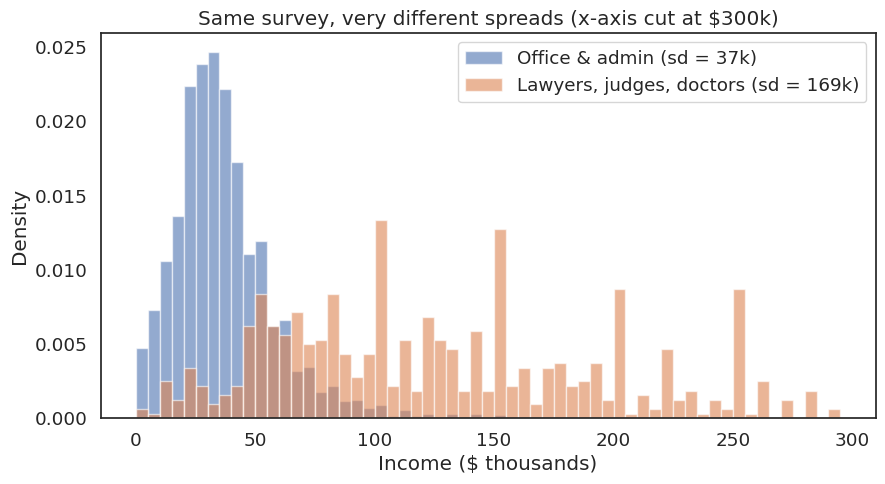

In [18]:
a = df.loc[df["occupation"] == "Lawyers, Judges,Physicans and dentists", "income"]
b = df.loc[df["occupation"] == "Office and Admin Support", "income"]

bins = np.arange(0, 300, 5)
plt.hist(b, bins=bins, density=True, alpha=0.6, label=f"Office & admin (sd = {b.std():.0f}k)")
plt.hist(a, bins=bins, density=True, alpha=0.6, label=f"Lawyers, judges, doctors (sd = {a.std():.0f}k)")
plt.xlabel("Income ($ thousands)"); plt.ylabel("Density")
plt.title("Same survey, very different spreads (x-axis cut at $300k)")
plt.legend(); plt.show()

### Exercise

1. Use `plot_histogram()` to plot the distribution of `age` (try 40 bins). Is it skewed? Does the mean differ much from the median?
2. Plot the distribution of years of schooling (`sch`). Pick a sensible number of bins, label it clearly, and explain the two big spikes.
3. For which of `income`, `age` and `sch` is the mean a good summary of a "typical" person? For which would you report the median?

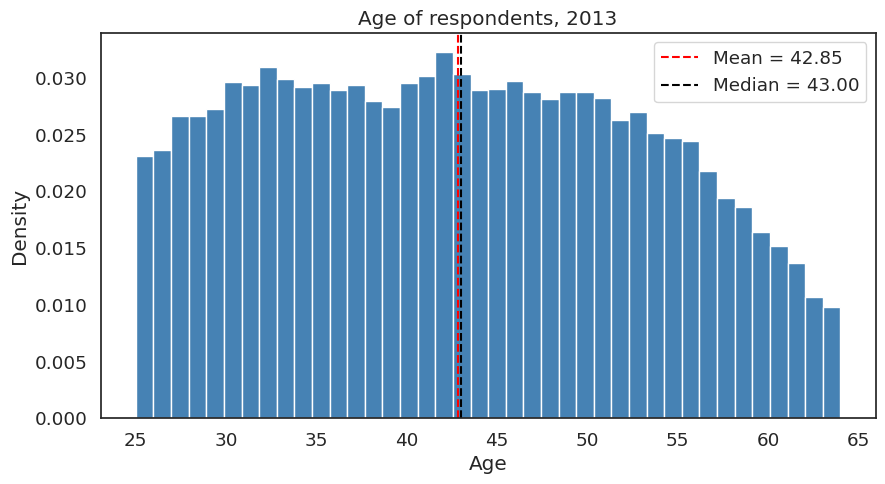

count    52923.000000
mean        42.845077
std         10.576333
min         25.000000
25%         34.000000
50%         43.000000
75%         51.000000
max         64.000000
Name: age, dtype: float64
mean -median = -0.1549231902953352


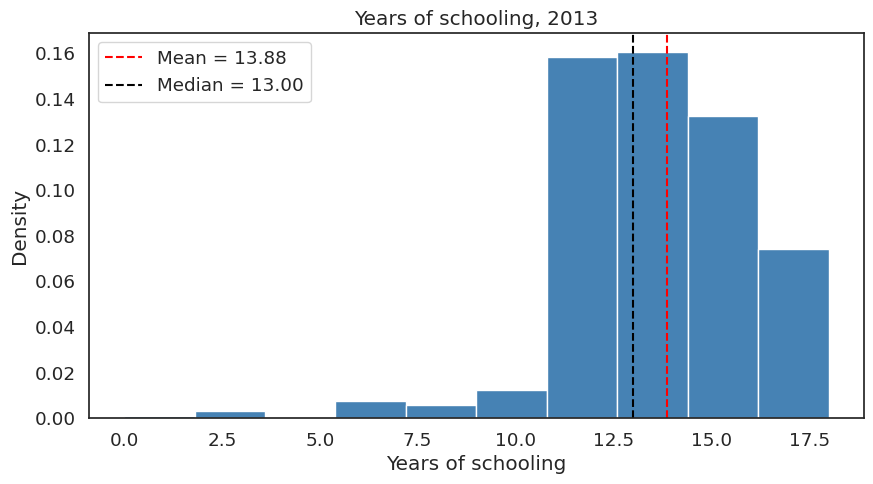

sch
0.0       111
2.5       282
5.5       705
7.5       565
9.0       611
10.0      583
11.0      734
12.0    14350
13.0     8927
14.0     6383
16.0    12611
18.0     7061
Name: count, dtype: int64
0.0 18.0 12


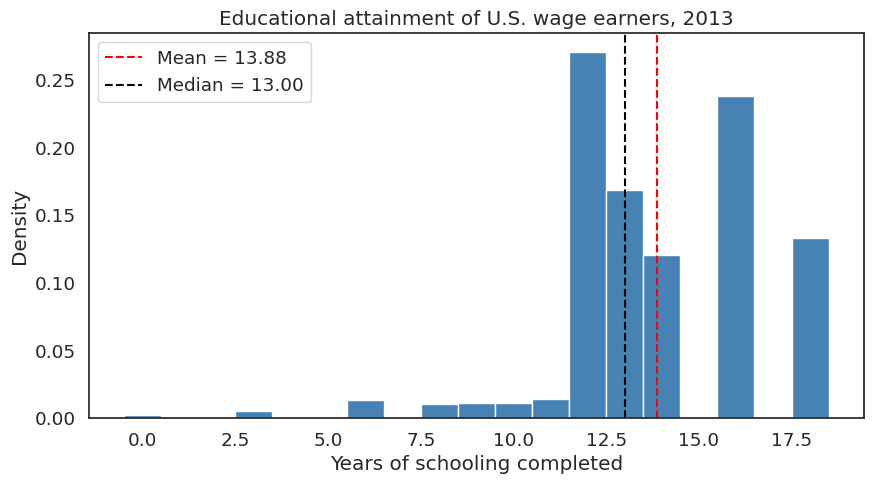

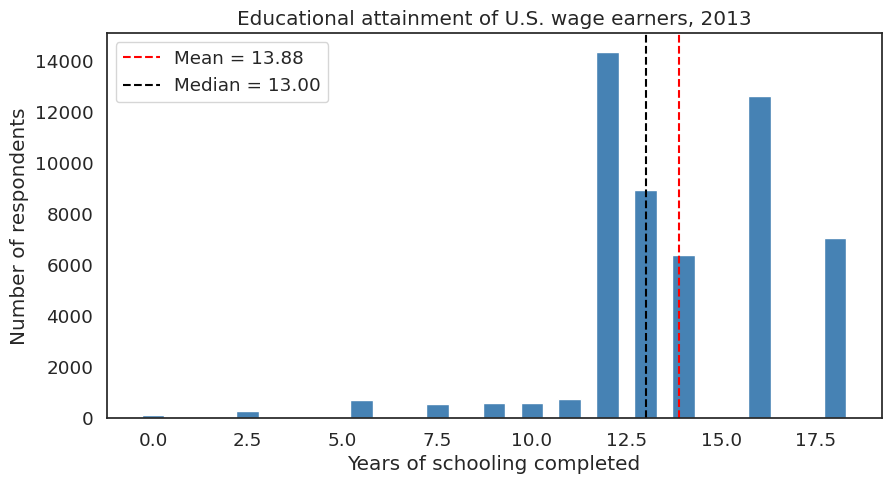

In [33]:
# your code here - ask Q about why hisotgrams are used here?
# I HAVE DONE THIS ONE IT DID NOT SAVE> Bruh.

#task 1
plot_histogram(df["age"], bins=40, xlab="Age", title="Age of respondents, 2013")
print(df["age"].describe())
print("mean -median =", df["age"].mean() - df["age"].median())

#task 2 > pick how many bins... - guess of ten
# 18 = top-code, master's upward (MA, JD, MD, PhD) into one value
plot_histogram(df["sch"], bins=10, xlab="Years of schooling", title="Years of schooling, 2013")
# actually count (not categorical)
print(df["sch"].value_counts().sort_index())
print(df["sch"].min(), df["sch"].max(), df["sch"].nunique())
#essentially 20 = bin no., want each bin to be approx a year?
# this plan keeps each bar approx 1 year wide, centred on it's year.
# Justification: one bin per possible value, edges at the half-years so bars centre on the data
plot_histogram(df["sch"], bins=np.arange(-0.5, 19.5, 1),
               xlab="Years of schooling completed",
               title="Educational attainment of U.S. wage earners, 2013")

# spikes post highschool, post degree. 18+ yrs grouped.
# 12 years: 14,350 people. High school completion.
# 16 years: 12,611 people. Four-year bachelor's degree.

# 13 yrs = started college, didn't finish, more people than have an associate's degree.
# mean describes a level of education no respondent has.
# mean = wrong summary for a bimodal variable.

# SUGGESTED: BAR CHART = more honest plot?
counts = df["sch"].value_counts().sort_index()

plt.bar(counts.index, counts.values, width=0.6, color="steelblue", edgecolor="white")
plt.axvline(df["sch"].mean(), color="red", linestyle="--", label=f"Mean = {df['sch'].mean():.2f}")
plt.axvline(df["sch"].median(), color="black", linestyle="--", label=f"Median = {df['sch'].median():.2f}")
plt.xlabel("Years of schooling completed")
plt.ylabel("Number of respondents")
plt.title("Educational attainment of U.S. wage earners, 2013")
plt.legend()
plt.show()

TASK3

age mean 42.91 / median 43.00 (difference −0.09, so not skewed)
>> TYPICAL = mean or median. Would opt for mean?

sch has 12 distinct values 0–18, spikes at 12 (14,350 people) and 16 (12,611), mean 13.88 vs median 13.

>> TYPICAL = Median (as mean falls in the valley of the 2?).

>> INCOME
DEFINITELY MEDIAN. LARGE skew.

Before moving on, we'll drop the small number of people earning over \$200k (about 1.6% of 2013 respondents), as in the lecture. This is a **choice**, and it changes the population we're describing (to "wage earners under \$200k"), so always report it.

In [21]:
print("Share of 2013 respondents earning over $200k:", round((df["income"] >= 200).mean(), 4))
df = df[df["income"] < 200]

Share of 2013 respondents earning over $200k: 0.0161


## 3. The Central Limit Theorem

### Estimating union membership in America

As in the lecture, let's ask: **what share of American workers are members of a labour union?**

The CPS only asks the union question to part of its sample (that's the `union = 0`, "N/A", group). So our **population** for this section is the 2013 respondents who were asked, and we create a binary variable: 1 = union member, 0 = not a member.

For the rest of the workshop we'll **pretend this group is the entire population**, so we know the true answer and can see how well samples recover it.

In [22]:
unions = df[df["union"] != 0].copy()
unions["member"] = (unions["union"] == 2).astype(int)

p = unions["member"].mean()
print(f"Population: {len(unions):,} people. True union membership rate: {p:.3f}")

Population: 8,697 people. True union membership rate: 0.141


### A sample of 7

Now imagine we can only afford to interview **7** random people. The code below draws one sample and computes its mean (= the share of union members in the sample). Run it several times.

In [23]:
sample = unions["member"].sample(7, replace=True)
print(sample.values, " -> sample mean:", round(sample.mean(), 3))

[1 0 0 0 0 0 0]  -> sample mean: 0.143


Quite often, *nobody* in the sample is a union member, so our estimate would be **0%**. How often? If each person has a probability $p$ of being a member, the chance that all 7 are not is $(1-p)^7$. Let's check that against a simulation of 10,000 samples.

The function below uses a `for` loop. Each time round the loop, it takes one random sample of `n` people (just like the cell above), computes the mean, and adds it to a list.

In [24]:
def sample_means(values, n, reps=10_000):
    # Take `reps` random samples of n people and return the mean of each one
    means = []
    for i in range(reps):
        sample = values.sample(n, replace=True)
        means.append(sample.mean())
    return np.array(means)

means7 = sample_means(unions["member"], n=7)
print("Theory:     P(all 7 are non-members) =", round((1 - p)**7, 3))
print("Simulation: share of samples with mean 0 =", round((means7 == 0).mean(), 3))

Theory:     P(all 7 are non-members) = 0.344
Simulation: share of samples with mean 0 = 0.345


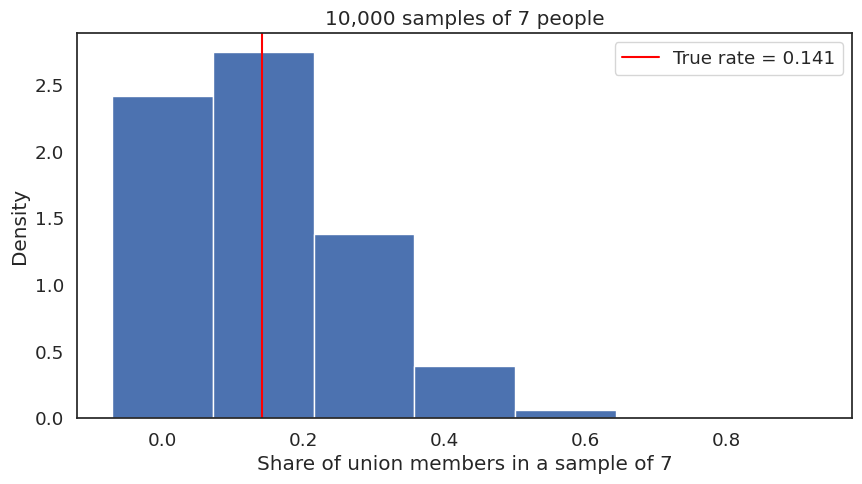

In [25]:
plt.hist(means7, bins=np.arange(-1/14, 1, 1/7), edgecolor="white", density=True)
plt.axvline(p, color="red", label=f"True rate = {p:.3f}")
plt.xlabel("Share of union members in a sample of 7")
plt.ylabel("Density")
plt.title("10,000 samples of 7 people")
plt.legend(); plt.show()

### Exercise

1. With samples of 7, what is the range of estimates you could plausibly get? Would you trust a single one?
2. Using the formula $(1-p)^n$, how likely is a sample of **1,000** people with *zero* union members? Now simulate it.
3. The lecture asked: "but *how* unlikely?" Answering that precisely is what the Central Limit Theorem is for.

In [35]:
# your code here

# Task 1 - have mean7, desribe the spread via range
print("min/max:", means7.min().round(3), means7.max().round(3))
print("middle 95%:", np.percentile(means7, [2.5, 97.5]).round(3))
# trust? -


min/max: 0.0 0.857
middle 95%: [0.    0.429]


Interpretation: sample of 7 could give you anything from 0% to 86% union membership, and 95% of the time you'd land somewhere between 0% and 43% — against a truth of 14.1%, so a single sample of 7 is useless.

In [36]:
# Task 2 - n=1,000, chance all 1,000 are non-members
print(f"Theory: {(1 - p)**1000:.3e}") #idk check

big = sample_means(unions["member"], n=1000) #get this.
print("Simulated share with zero:", (big == 0).mean())
print("Simulated range:", big.min().round(3), "to", big.max().round(3))


Theory: 6.837e-67
Simulated share with zero: 0.0
Simulated range: 0.103 to 0.187


INTERPRETATION: The chance of a 1,000-person sample containing zero union members is 6.8 × 10⁻⁶⁷.
Which is why 10,000 simulated samples produced not a single one.
Reality: They all landed between 10.3% and 18.7%.

In [38]:
from scipy import stats
# Task 3 - how unlikely...
# normal dist with standard error
se = np.sqrt(p * (1 - p) / 1000)
print("simulated SD:", big.std().round(4), "| CLT formula:", se.round(4))
print("zero is", round((0 - p) / se, 1), "standard errors below p")
print("P(off by >= 0.02):", round(2 * stats.norm.sf(0.02 / se), 4))

simulated SD: 0.011 | CLT formula: 0.011
zero is -12.8 standard errors below p
P(off by >= 0.02): 0.0694


INTERPRETATION:

CLT formula perfectly gets the simulated spread (both 0.011), putting zero ... 12.8 standard errors below the truth.

The useful number is the last one: even with 1,000 people there's still a 6.9% chance your estimate misses the true rate by 2 percentage points or more.

### The sampling distribution becomes normal

The distribution of sample means is called the **sampling distribution**. Watch what happens to it as the sample size grows. The black curve is a normal distribution with the same mean and standard deviation as the simulated means.

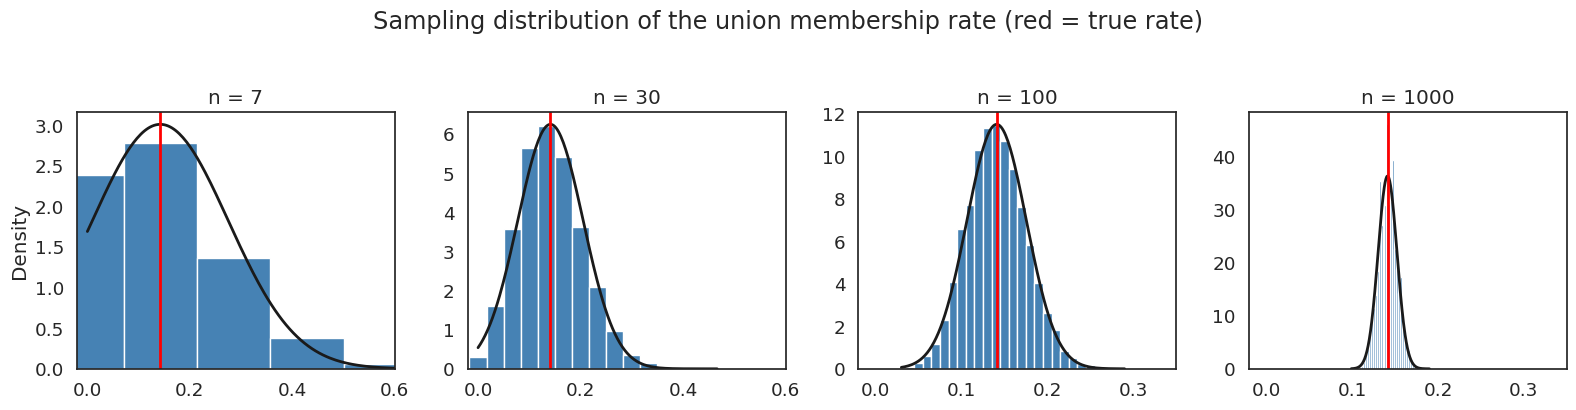

In [27]:
def plot_sampling_distribution(means, ax, true_mean, title, n=None):
    # For a 0/1 variable the sample mean can only take the values 0, 1/n, 2/n, ...
    # so if n is given (and small) we use one bar per possible value.
    bins = (np.arange(n + 2) - 0.5) / n if (n is not None and n <= 200) else 40
    ax.hist(means, bins=bins, density=True, color="steelblue", edgecolor="white")
    mu, sd = means.mean(), means.std()
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, norm.pdf(xs, mu, sd), "k", lw=2)
    ax.axvline(true_mean, color="red", lw=2)
    ax.set_title(title)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, n in zip(axes, [7, 30, 100, 1000]):
    plot_sampling_distribution(sample_means(unions["member"], n), ax, p, f"n = {n}", n=n)
    ax.set_xlim(-0.02, 0.6 if n < 100 else 0.35)
axes[0].set_ylabel("Density")
fig.suptitle("Sampling distribution of the union membership rate (red = true rate)", y=1.03)
plt.tight_layout(); plt.show()

The underlying variable is just 0s and 1s, as far from a bell curve as it gets. Yet with big enough samples the **sample means** are approximately normal and centred on the true value. That is the **Central Limit Theorem**:

> If you take sufficiently large random samples, the distribution of sample means is approximately normal, *regardless of the distribution of the underlying population*.

### It works for skewed variables too

Income is heavily right-skewed. Compare the distribution of individual incomes (left) with the distribution of the means of samples of 500 people (right).

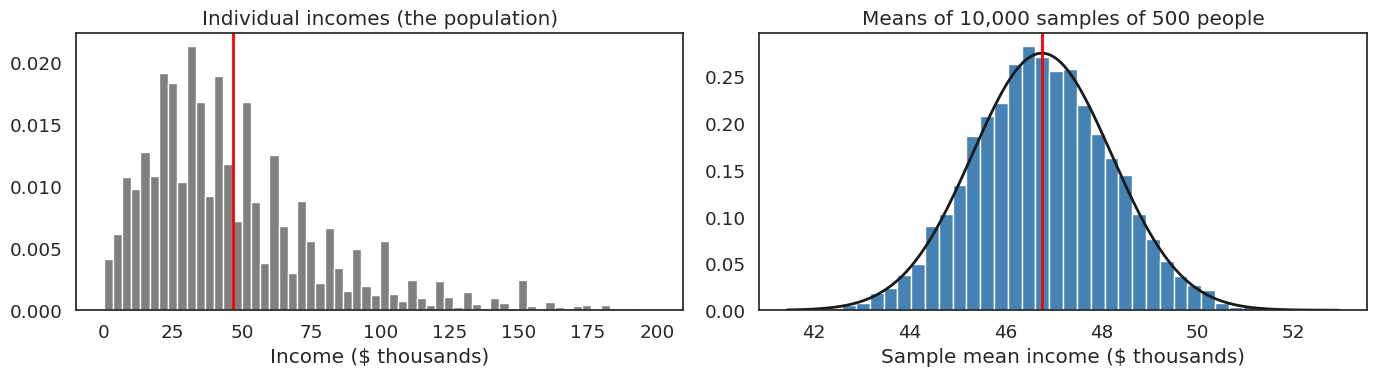

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df["income"], bins=60, density=True, color="grey", edgecolor="white")
axes[0].axvline(df["income"].mean(), color="red", lw=2)
axes[0].set(title="Individual incomes (the population)", xlabel="Income ($ thousands)")
plot_sampling_distribution(sample_means(df["income"], 500), axes[1], df["income"].mean(),
                           "Means of 10,000 samples of 500 people")
axes[1].set_xlabel("Sample mean income ($ thousands)")
plt.tight_layout(); plt.show()

### Exercise

1. Repeat the two-panel plot for `age` and for `sch` (years of schooling). How non-normal are the raw distributions? Are the sampling distributions normal?
2. Try a small sample size (e.g. n = 5) for income. At what sample size does the sampling distribution start to look normal? Is it the same for a symmetric variable like age?

In [29]:
# your code here

### The standard error

The standard deviation of the sampling distribution is called the **standard error** (SE). It tells us how far a sample mean typically lands from the population mean:

$$SE = \frac{\sigma}{\sqrt{n}}$$

where $\sigma$ is the population standard deviation and $n$ is the sample size. Because the sampling distribution is normal, the **68-95-99.7 rule** applies: about 68%, 95% and 99.7% of sample means land within 1, 2 and 3 SEs of the population mean. Let's check it for samples of 1,000. (Next week we look at the standard error in more detail.)

In [30]:
n = 1000
se = unions["member"].std() / np.sqrt(n)
means = sample_means(unions["member"], n)

print("Standard error:", round(se, 4))
print("Share within 1 SE:", (abs(means - p) < 1 * se).mean())
print("Share within 2 SE:", (abs(means - p) < 2 * se).mean())
print("Share within 3 SE:", (abs(means - p) < 3 * se).mean())

Standard error: 0.011
Share within 1 SE: 0.6861
Share within 2 SE: 0.9586
Share within 3 SE: 0.9978


# Assessed Question

The URL below contains the 2013 CPS respondents: one row per person, with the same columns as the `cps` dataframe we used above.

https://oballinger.github.io/BASC0005/data/assessed/w05_cps_2013.csv

Note that the file may have been corrupted; some values or labels may be wrong, so make sure to sense-check your data before answering.

**QUESTION: Treat all 2013 respondents with a reported wage income (incwage > 0) as the population. Using SE = sigma/sqrt(n) and the 68-95-99.7 rule, what is the smallest sample size n such that 95% of sample means fall within $1,000 of the population mean income? Use .std() for sigma.**

In [31]:
# your code here

## Recap

1. A **population** is the set of all relevant measurements; a **sample** is the part we observe. Always ask how the sample was selected: this CPS extract only covers 25-64 year-old wage earners.
2. Use the **median** for skewed variables, the **mode** for categorical ones, and check extreme values before trusting a mean.
3. **Central Limit Theorem:** for sufficiently large random samples, sample means are approximately normally distributed, whatever the shape of the underlying data.
4. The **standard error** $\sigma/\sqrt{n}$ tells us how much a sample mean bounces around; about 95% of sample means fall within 2 SEs of the population mean.

Next week we look at the **standard error** in more detail, turn it into **confidence intervals** and **hypothesis tests**, and meet a Bayesian way to estimate union membership.